In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [44]:
df = pd.read_csv("power_marketing_customer_electricity_dataset.csv")

In [45]:
df.describe()

,record_id,customer_id,hour,day_of_week,month,is_weekend,age,monthly_income_usd,household_size,home_area_sqft,...,entertainment_usage_hours,ev_charging_kwh,electricity_consumption_kwh,pricing_influence_score,weather_influence_score,appliance_influence_score,household_influence_score,previous_hour_consumption_kwh,previous_day_same_hour_consumption_kwh,rolling_24h_avg_consumption_kwh
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,...,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,7500.500000,10376.025200,11.500000,2.998400,5.816000,0.284800,48.521133,4099.846400,3.990933,1611.946200,...,0.329036,0.065368,2.002760,2.485628,6.330095,1.026010,4.204896,2.002417,1.993749,1.994318
std,4330.271354,216.437105,6.922417,1.997264,3.195063,0.451334,15.635293,2032.168958,1.992197,681.695097,...,0.244390,0.404672,0.717984,2.331150,4.066638,0.593636,1.094206,0.719083,0.329448,0.308493
min,1.000000,10001.000000,0.000000,0.000000,1.000000,0.000000,22.000000,600.000000,1.000000,450.000000,...,0.000000,0.000000,0.280000,0.000000,0.002000,0.079000,1.216000,0.280000,0.426000,0.426000
25%,3750.750000,10188.000000,5.750000,1.000000,3.000000,0.000000,35.000000,2346.500000,2.000000,1019.000000,...,0.143000,0.000000,1.485000,0.550000,3.161750,0.570000,3.430000,1.485000,1.822000,1.829000
50%,7500.500000,10378.000000,11.500000,3.000000,6.000000,0.000000,49.000000,4096.500000,4.000000,1601.000000,...,0.260000,0.000000,1.939000,1.810000,5.414000,0.921000,4.203000,1.939000,1.977000,1.978000
75%,11250.250000,10564.000000,17.250000,5.000000,8.000000,1.000000,62.000000,5874.250000,6.000000,2207.000000,...,0.508000,0.000000,2.397250,3.620000,9.002000,1.421000,4.986000,2.397000,2.136000,2.131000
max,15000.000000,10750.000000,23.000000,6.000000,12.000000,1.000000,75.000000,7599.000000,7.000000,2799.000000,...,1.000000,8.305000,9.379000,13.110000,19.528000,8.386000,7.248000,9.379000,6.115000,5.296000


In [46]:
df.isnull().sum()

record_id                                 0
customer_id                               0
timestamp                                 0
hour                                      0
day_of_week                               0
month                                     0
is_weekend                                0
season                                    0
customer_type                             0
age                                       0
monthly_income_usd                        0
household_size                            0
home_area_sqft                            0
appliance_count                           0
has_solar_panel                           0
has_ev                                    0
tariff_scheme                             0
contract_type                             0
temperature_c                             0
humidity_percent                          0
peak_hour                                 0
price_per_kwh                             0
ac_usage_hours                  

In [47]:
print((df.columns.tolist()))


['record_id', 'customer_id', 'timestamp', 'hour', 'day_of_week', 'month', 'is_weekend', 'season', 'customer_type', 'age', 'monthly_income_usd', 'household_size', 'home_area_sqft', 'appliance_count', 'has_solar_panel', 'has_ev', 'tariff_scheme', 'contract_type', 'temperature_c', 'humidity_percent', 'peak_hour', 'price_per_kwh', 'ac_usage_hours', 'heater_usage_hours', 'washing_machine_usage', 'lighting_usage_hours', 'cooking_usage_hours', 'entertainment_usage_hours', 'ev_charging_kwh', 'electricity_consumption_kwh', 'pricing_influence_score', 'weather_influence_score', 'appliance_influence_score', 'household_influence_score', 'previous_hour_consumption_kwh', 'previous_day_same_hour_consumption_kwh', 'rolling_24h_avg_consumption_kwh', 'consumption_behavior_category']


In [48]:
target = "electricity_consumption_kwh"
features = ["household_size", "monthly_income_usd", "age"]

In [49]:
df[[target] + features].head()

,electricity_consumption_kwh,household_size,monthly_income_usd,age
0,2.058,1,3747,66
1,1.253,2,5083,38
2,3.607,7,4405,26
3,0.662,3,6962,59
4,1.496,4,3972,38


assumption 1: linearity

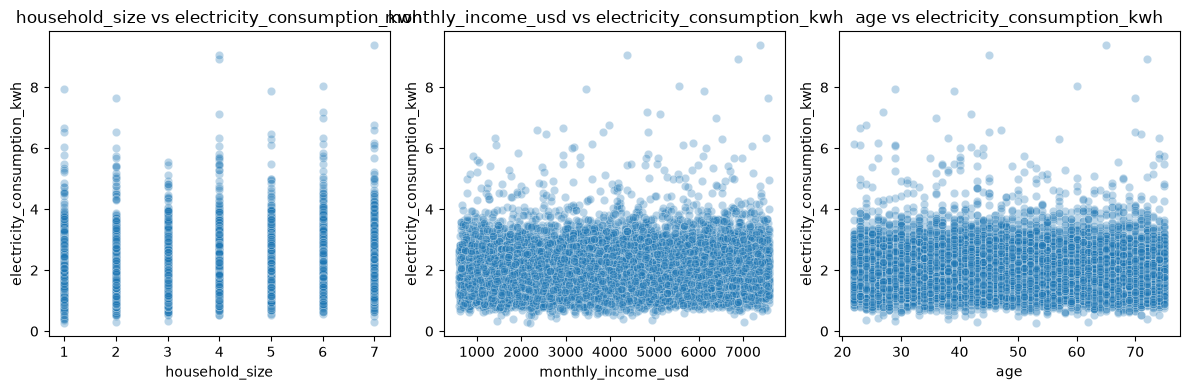

In [57]:
plt.figure(figsize=(12, 4))
for i, col in enumerate(features, 1):
    plt.subplot(1, 3, i)
    sns.scatterplot(x=df[col], y=df[target], alpha=0.3)
    plt.title(f"{col} vs {target}")
plt.tight_layout()
plt.show()

assumption 2: absence of multicollinearity

correlation matrix:
                    household_size  monthly_income_usd       age
household_size            1.000000           -0.002641  0.005237
monthly_income_usd       -0.002641            1.000000  0.002974
age                       0.005237            0.002974  1.000000


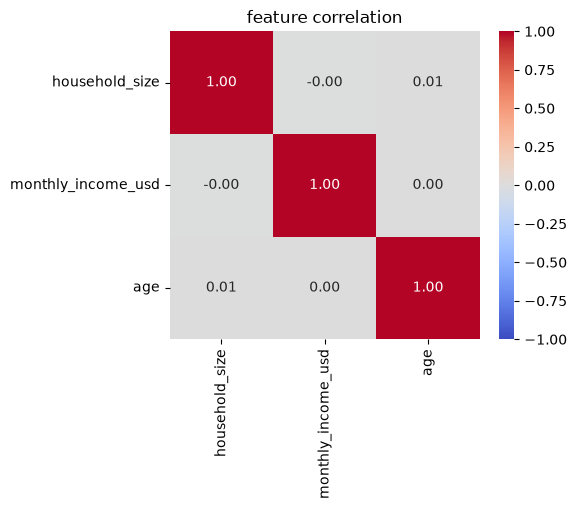

In [59]:
corr_matrix = df[features].corr()
print("correlation matrix:")
print(corr_matrix)

plt.figure(figsize=(5, 4))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("feature correlation")
plt.show()

In [53]:
x = df[features]
y = df[target]

model = LinearRegression()
model.fit(x, y)

y_pred = model.predict(x)
residuals = y - y_pred

assumption 3: homoscedasticity

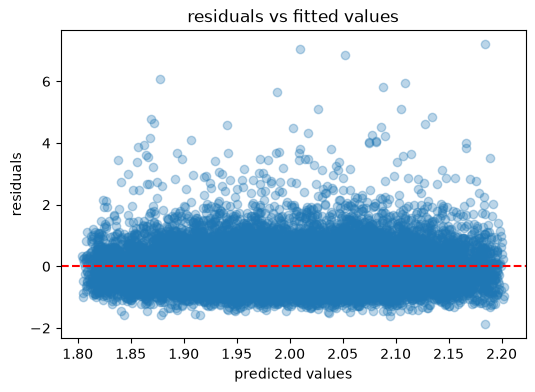

In [54]:
plt.figure(figsize=(6, 4))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("predicted values")
plt.ylabel("residuals")
plt.title("residuals vs fitted values")
plt.show()

assumption 4: normality of residuals

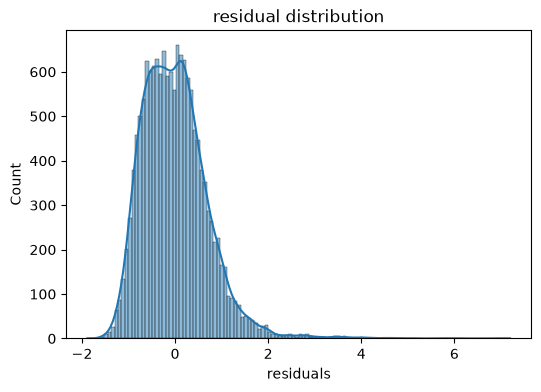

In [55]:
plt.figure(figsize=(6, 4))
sns.histplot(residuals, kde=True)
plt.xlabel("residuals")
plt.title("residual distribution")
plt.show()

assumption 5: independence of residuals

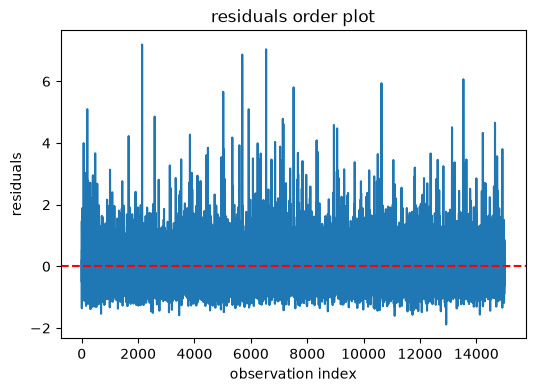

In [56]:
plt.figure(figsize=(6, 4))
plt.plot(residuals.values)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("observation index")
plt.ylabel("residuals")
plt.title("residuals order plot")
plt.show()



**Decision: Linear regression is suitable for this dataset.**

Assumptions: 
1. Linearity
2. Independence
3. Homoscedasiticity
4. normality of residuals
5. Absence of perfect multicollinearity

Because the data lacks linear trends and exhibits right-skewed residuals, standard linear regression is not suitable here. To make linear regression work or improve performance, the target variable would need a log transformation (to handle the skewness/tail) and non-linear terms or additional relevant features (e.g., appliance usage, temperature) would need to be included.